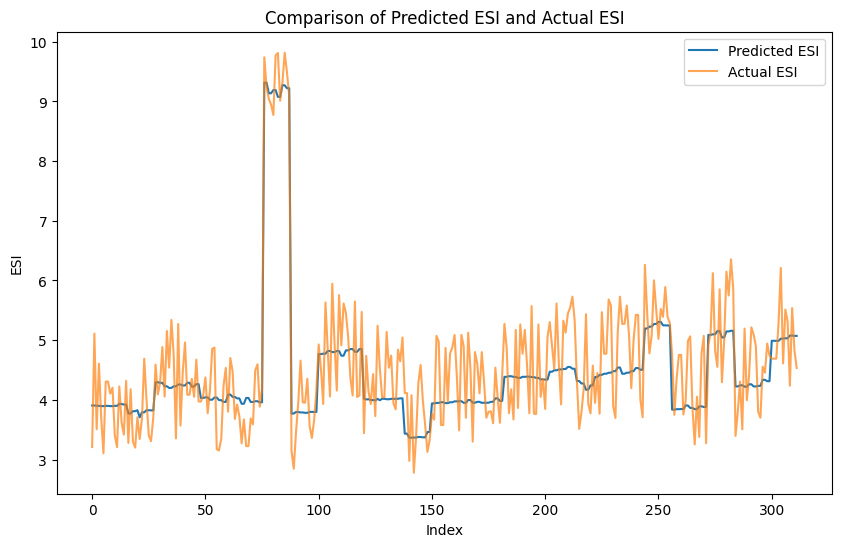

Mean Squared Error: 0.3816776276386109
Root Mean Squared Error: 0.6178006374540341
R-squared: 0.7364390962043125


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("../data/Complete_Dataset_updated.csv")

data['predicted_esi'] = 0.32* data['Rainfall'] + 0.12* data['TEMP_MAX'] + 0.99* data['NDVI']

# Plotting the actual ESI and the predicted ESI
plt.figure(figsize=(10, 6))
plt.plot(data['predicted_esi'], label='Predicted ESI')
plt.plot(data['Environmental Suitability Index'], label='Actual ESI', alpha=0.7)
plt.title('Comparison of Predicted ESI and Actual ESI')
plt.xlabel('Index')
plt.ylabel('ESI')
plt.legend()
plt.show()

mse = mean_squared_error(data['Environmental Suitability Index'], data['predicted_esi'])
rmse = np.sqrt(mse)
r_squared = r2_score(data['Environmental Suitability Index'], data['predicted_esi'])

print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R-squared: {r_squared}')

In [13]:
#D3:

import numpy as np
import random
import time
import pandas as pd
from solution import solution

# Load the dataset
data_df = pd.read_csv("../data/Complete_Dataset_updated.csv")
data = { #a dictionary for easy access data
    'rainfall': data_df['Rainfall'].values,
    'max_temperature': data_df['TEMP_MAX'].values,
    'vegetation_index': data_df['NDVI'].values,
    'actual_esi': data_df['Environmental Suitability Index'].values
}
# here we define the objFun to the GA  which calc the MSE between pred, actual.
def esi_objective_function(weights):
    # Compute the predicted Environmental Suitability Index (ESI) based on input weights
    predicted_esi = weights[0] * data['rainfall'] + weights[1] * data['max_temperature'] + weights[2] * data['vegetation_index']
    mse = np.mean((data['actual_esi'] - predicted_esi) ** 2)
    return mse

def calculateCost(objf, population, popSize, lb, ub):
    # Calculate the cost for each individual in the population
    scores = np.full(popSize, np.inf)
    for i in range(popSize):
        population[i] = np.clip(population[i], lb, ub)  # Ensure weights are within bounds
        scores[i] = objf(population[i])
    return scores


#this fun select the paris we will do the cross for them , the section is based on the fitenss
def pairSelection(population, scores, popSize):
    # Select pairs for crossover using roulette wheel selection
    max_score = max(scores)
    inverted_scores = [max_score - score for score in scores]  # Invert scores for minimization problem
    total_fitness = sum(inverted_scores)
    normalized_scores = [score / total_fitness for score in inverted_scores]
    cumulative_probs = np.cumsum(normalized_scores)
    parent1Id = np.searchsorted(cumulative_probs, random.random())
    parent2Id = parent1Id
    while parent2Id == parent1Id:
        parent2Id = np.searchsorted(cumulative_probs, random.random())
    return population[parent1Id].copy(), population[parent2Id].copy()


#this fun creats the new pop from the crossover
def crossoverPopulation(population, scores, popSize, crossoverProbability, keep):
    # Perform crossover to generate new population
    newPopulation = np.zeros_like(population)
    newPopulation[:keep] = population[:keep]  # Keep best individuals
    for i in range(keep, popSize, 2):
        parent1, parent2 = pairSelection(population, scores, popSize)
        if random.random() < crossoverProbability:
            point = random.randint(1, len(parent1) - 1)
            newPopulation[i, :point], newPopulation[i + 1, :point] = parent1[:point], parent2[:point]
            newPopulation[i, point:], newPopulation[i + 1, point:] = parent2[point:], parent1[point:]
        else:
            newPopulation[i], newPopulation[i + 1] = parent1, parent2
    return newPopulation

# Apply mutation to make i more variability
def mutation(population, popSize, mutationProbability, keep, lb, ub):
    # Apply mutation to individuals in the population
    for i in range(keep, popSize):
        if random.random() < mutationProbability:
            mutationIndex = random.randint(0, len(population[i]) - 1)
            population[i][mutationIndex] = random.uniform(lb[mutationIndex], ub[mutationIndex])
            
# Apply removeDuplications to make i more variability
def clearDups(population, lb, ub):
    # Remove duplicate individuals from the population
    unique = np.unique(population, axis=0)
    if len(unique) < len(population):
        needed = len(population) - len(unique)
        additional = np.random.uniform(lb, ub, (needed, len(lb)))
        unique = np.vstack((unique, additional))
    return unique

# Sort the population based on their fitness scores
def sortPopulation(population, scores):
    # Sort the population based on scores
    indices = scores.argsort()
    return population[indices], scores[indices]

#THIS IS THE MAIN FUNCITON!
def GA(objf, lb, ub, dim, popSize, iters):
    timerStart = time.time()
    s = solution()
    ga = np.random.uniform(low=lb, high=ub, size=(popSize, dim))
    scores = calculateCost(objf, ga, popSize, lb, ub)
    convergence_curve = np.zeros(iters)
    
    for l in range(iters):
        if l == iters - 1:  # Print statements only for the last iteration
            print("\nFinal Iteration:")
        
        # Selection and Crossover
        ga = crossoverPopulation(ga, scores, popSize, 1, 2)
        if l == iters - 1:
            print("\nAfter Selection and Crossover:")
            for idx, individual in enumerate(ga):
                print(f"Individual {idx}: {individual}")

        # Mutation
        mutation(ga, popSize, 0.01, 2, lb, ub)
        if l == iters - 1:
            print("\nAfter Mutation:")
            for idx, individual in enumerate(ga):
                print(f"Individual {idx}: {individual}")

        # Remove duplicates
        ga = clearDups(ga, lb, ub)
        if l == iters - 1:
            print("\nAfter Clearing Duplicates:")
            for idx, individual in enumerate(ga):
                print(f"Individual {idx}: {individual}")

        # Calculate fitness
        scores = calculateCost(objf, ga, popSize, lb, ub)
        if l == iters - 1:
            print("\nAfter Calculating Cost (Fitness):")
            for idx, score in enumerate(scores):
                print(f"Individual {idx}: Fitness: {score}")

        # Sorting the population
        ga, scores = sortPopulation(ga, scores)
        if l == iters - 1:
            print("\nAfter Sorting by Fitness:")
            for idx, (individual, score) in enumerate(zip(ga, scores)):
                print(f"Individual {idx}: Weights: {individual}, Fitness: {score}")

        convergence_curve[l] = scores[0]

    # Capture the best individual and score from the final population
    bestIndividual = ga[0]
    bestScore = scores[0]
    s.bestIndividual = bestIndividual
    s.bestScore = bestScore
    s.convergence = convergence_curve
    s.executionTime = time.time() - timerStart

    return s

# Define GA parameters as our assignment need
lb = [0, 0, 0]  # Lower bounds 
ub = [1, 1, 1]  # Upper bounds 
dim = 3  # Number of dimensions ( w )
popSize = 30  # Population size
iters = 50  # Number of iterations

# Apply the GA
best_solution = GA(esi_objective_function, lb, ub, dim, popSize, iters)
print("Best weights found:", best_solution.bestIndividual)
print("Best fitness achieved:", best_solution.bestScore)



Final Iteration:

After Selection and Crossover:
Individual 0: [0.34081451 0.12798687 0.79336462]
Individual 1: [0.34081451 0.12798687 0.43940224]
Individual 2: [0.16575149 0.12054226 0.270236  ]
Individual 3: [0.22849342 0.39838338 0.79336462]
Individual 4: [0.4847817  0.12054226 0.35653293]
Individual 5: [0.16575149 0.41521136 0.71212235]
Individual 6: [0.34081451 0.39838338 0.37758973]
Individual 7: [0.76652032 0.20223156 0.43940224]
Individual 8: [0.16575149 0.12054226 0.35653293]
Individual 9: [0.99186323 0.33952214 0.31854575]
Individual 10: [0.26364986 0.44218363 0.43940224]
Individual 11: [0.34081451 0.39838338 0.00275166]
Individual 12: [0.01750001 0.12798687 0.35653293]
Individual 13: [0.34081451 0.12054226 0.79336462]
Individual 14: [0.01750001 0.39838338 0.79336462]
Individual 15: [0.99186323 0.12798687 0.43940224]
Individual 16: [0.34081451 0.12798687 0.79336462]
Individual 17: [0.99186323 0.12798687 0.43940224]
Individual 18: [0.4847817  0.41521136 0.35653293]
Individual